# EAD afín: exposición y fecha de default bajo salidas competidoras
## Pregunta y utilidad
¿Podemos integrar amortización entre fechas irregulares sin reinterpretar hazards ni refinar artificialmente todo el calendario? Continuamos `calendar_notebook.ipynb`30: integración exacta del descuento con EAD constante. Ahora EAD condicional a no haber salido es afín por tramo. Es adaptación de ingeniería de integrales conocidas, no fórmula financiera inédita ni validación empírica.

H técnica fijada en config antes de interpretar: error absoluto <1e-8 unidades monetarias frente a Simpson2048 y no peor que EAD al punto medio dentro de esa tolerancia. Datos sintéticos; no estimamos PD, causalidad, IFRS9 ni desempeño de cartera.

## Marco teórico y derivación
En tramo de duración $\Delta>0$ años, causas $d,p\ge0$ año$^{-1}$ y descuento $r\ge0$ año$^{-1}$, supervivencia $S(t+u)=S_t e^{-(d+p)u}$. EAD monetaria $E(u)=E_0+(E_1-E_0)u/\Delta$, extremos no negativos; LGD $L\in[0,1]$.

Original30: $EL_i=S_tLe^{-rt}E_0[d/(d+p+r)](1-e^{-(d+p+r)\Delta})$. Limitación: mantiene EAD fija mientras amortiza el préstamo. Propuesta: integrar $E(u)$ con la densidad de default descontada, sin cambiar probabilidades de salida.

Sea $a=d+p+r$, $x=a\Delta$. Integración por partes da $I_0=\int_0^\Delta e^{-au}du=(1-e^{-x})/a$ y $I_1=\int_0^\Delta ue^{-au}du=[1-(1+x)e^{-x}]/a^2$. Así:
$$EL_i=S_tLe^{-rt}d[E_0I_0+(E_1-E_0)I_1/\Delta].$$
La forma directa cancela cerca de cero. Dividimos por $I_0$: $w=I_1/(\Delta I_0)=1/x-1/(e^x-1)$ y
$$EL_i=S_tLe^{-rt}\frac d a(1-e^{-x})[(1-w)E_0+wE_1].$$
`discounted_mean_fraction` usa $w=1/2-x/12+x^3/720-x^5/30240$ para $x<.01$ y $1/x$ para $x>700$. El truncamiento pequeño es controlado numéricamente frente a Decimal75. No se denomina un teorema nuevo. Si $a=0$, necesariamente $d=0$, pérdida cero. Cada factor salvo EAD es adimensional: EL queda en dinero.

In [1]:
from src.affine import project_affine,discounted_mean_fraction
from src.affine_experiment import simpson
import json, math
from pathlib import Path
from IPython.display import display, Image
root=Path.cwd()
anchor=project_affine([1.],[.24],[1.2],[100.],[20.])
print(anchor)
assert abs(anchor.exact_loss-simpson(100.,20.,.24,1.2,.06,1.))<1e-8

AffineResult(exact_loss=3.8955123843562323, midpoint_loss=3.3560777081587836, endpoint_loss=1.1186925693862613, constant_start_loss=5.593462846931305, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176)


## Propiedades y mecanismo
$w$ es una media de $u/\Delta$ ponderada por una densidad positiva decreciente; $0\le w\le1/2$ para $a\ge0$. Por ello en amortización $EL_{endEAD}\le EL_{midEAD}\le EL_{affine}\le EL_{startEAD}$. Bajo exposición creciente se invierte la desigualdad. Estos baselines integran exactamente descuento y hazards: solo aproximan EAD, por lo que no atribuimos a amortización una mejora por descuento.

EAD constante recupera la API30. La integral es aditiva al partir tramos conservando la MISMA función afín y hazards. La API permite saltos entre tramos, no pagos aleatorios ni EAD dependiente del default latente. El $d$ es hazard por causa, no hazard de subdistribución Fine–Gray.

In [2]:
edges=[0.,.03,.2,.51,1.]
dt=[b-a for a,b in zip(edges,edges[1:])]
split=project_affine(dt,[.24]*4,[1.2]*4,[100-80*t for t in edges[:-1]],[100-80*t for t in edges[1:]])
print('Irregular partition error money:',abs(split.exact_loss-anchor.exact_loss))
assert abs(split.exact_loss-anchor.exact_loss)<1e-12
for x in [0.,1e-12,.01,1.,1000.]: print('x, mean fraction:',x,discounted_mean_fraction(x))

Irregular partition error money: 8.881784197001252e-16
x, mean fraction: 0.0 0.5
x, mean fraction: 1e-12 0.4999999999999167
x, mean fraction: 0.01 0.4991666680555653
x, mean fraction: 1.0 0.41802329313067355
x, mean fraction: 1000.0 0.001


## Experimentos y comparación justa
36 regímenes completos: EAD100→20,20→100,100→100,100→0; causas/descuento(.24,1.2,.06),(.01,0,0),(1,3,.2); duración.1,1,3años. Simpson2048 calcula el integrando directamente; no reutiliza w. Igual DGP/horizonte/información; oráculo gasta2049 evaluaciones contra O(1). Tiempo mediana7repeticiones50llamadas sin imports/instalación, memoria Python tracemalloc; no RSS ni coste nube. No hay intervalos estadísticos porque no hay muestreo.

{
  "anchor": {
    "exact_loss": 3.8955123843562323,
    "midpoint_loss": 3.3560777081587836,
    "endpoint_loss": 1.1186925693862613,
    "constant_start_loss": 5.593462846931305,
    "default_probability": 0.12717870688631303,
    "prepayment_probability": 0.6358935344315652,
    "survival": 0.23692775868212176
  },
  "cases": 36,
  "max_abs_error_vs_simpson2048": 1.0558665053395089e-10,
  "timings": {
    "closed_form": {
      "median_seconds": 5.0700199994935246e-06,
      "samples_seconds": [
        5.350240001007478e-06,
        5.425340000329015e-06,
        4.79479999967225e-06,
        4.7625599995626545e-06,
        5.0700199994935246e-06,
        4.780579999987822e-06,
        5.41494000003695e-06
      ],
      "peak_python_bytes": 752
    },
    "simpson2048": {
      "median_seconds": 0.00044398681999950894,
      "samples_seconds": [
        0.0004481556999996883,
        0.00045537953999996716,
        0.00044815648000053445,
        0.00044297189999952023,
        0

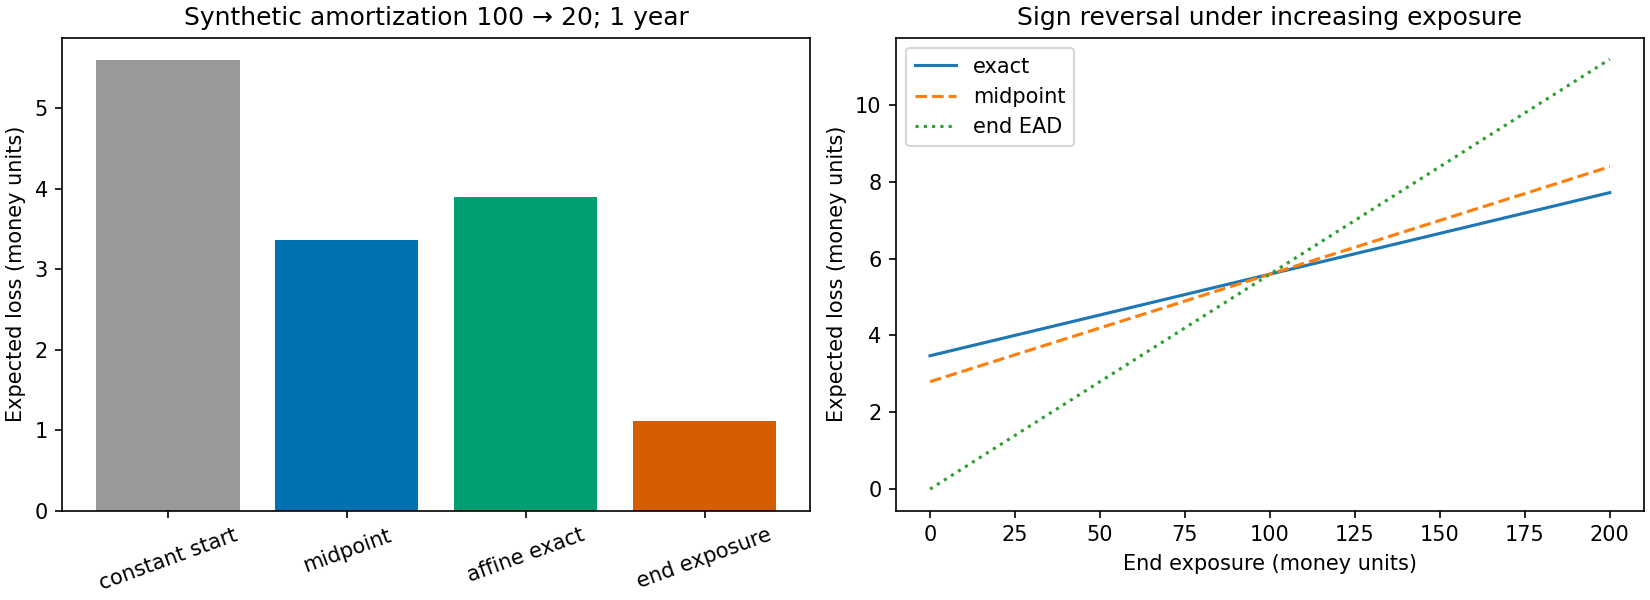

In [3]:
metrics=json.loads((root/'results/affine_metrics.json').read_text())
print(json.dumps(metrics,indent=2))
assert metrics['passed']
display(Image(filename=str(root/'results/affine.png')))

## Ablation y resultado negativo
Eliminar pendiente (E1=E0) elimina toda ganancia contra constante inicial; con default0 no hay pérdida. EADcreciente refuta el uso universal del cierre como cota inferior. Punto medio es competitivo cuando x pequeño y no requiere asumir superioridad científica del closed-form. La trayectoria real de saldo puede tener saltos de pagos: representarlos en límites del tramo; interpolar un pago discreto como amortización continua cambia el modelo económico.

In [4]:
flat=project_affine([1.],[.24],[1.2],[100.],[100.])
growing=project_affine([1.],[.24],[1.2],[20.],[100.])
assert abs(flat.exact_loss-flat.midpoint_loss)<1e-12
assert growing.endpoint_loss>growing.exact_loss
assert project_affine([1.],[0.],[0.],[100.],[0.],discount_force=0.).exact_loss==0.
print('Constant negative:',flat)
print('Increasing negative:',growing)
print((root/'results/tests.txt').read_text())

Constant negative: AffineResult(exact_loss=5.593462846931306, midpoint_loss=5.593462846931306, endpoint_loss=5.593462846931306, constant_start_loss=5.593462846931305, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176)
Increasing negative: AffineResult(exact_loss=2.816643031961335, midpoint_loss=3.3560777081587836, endpoint_loss=5.593462846931306, constant_start_loss=1.118692569386261, default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176)
test_constant_reduces_to_original (test_affine.AffineTests.test_constant_reduces_to_original) ... ok
test_decimal_oracle_small_large (test_affine.AffineTests.test_decimal_oracle_small_large) ... ok
test_invalid (test_affine.AffineTests.test_invalid) ... ok
test_negative_direction_and_zero (test_affine.AffineTests.test_negative_direction_and_zero) ... ok
test_partition_invariance_irregular (test_affine.AffineTests.test_partition_inv

## Conclusión calculada y límites
El reporte visible permite decidir si continuar el motor: continuar extensión si H y conservación se sostienen, ajustar si fallan endpoints/semántica de pagos, cerrar uso real sin datos condicionales/calibración aprobados. Ahora se puede valorar exposición afín y calendarios irregulares conservando contrato30; no predecir comportamiento real. `informe31.md` contiene lectura numérica, matriz bibliográfica y rúbricas. No reivindicamos originalidad disciplinar. Ejecución real secuencial IPython en proceso nuevo; no kernel aislado ni QA de interfaz Jupyter.